In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from sklearn.neighbors import KNeighborsClassifier

In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../../../Edge-IIoTset_ML-112.csv')

In [4]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [5]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [6]:
# Load precomputed selected features
feature_list_path = "../selected_features_15class_mi.pkl"
with open(feature_list_path, "rb") as f:
    selected_features = pickle.load(f)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.4, random_state=42)

In [8]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (91347, 40)
X_test shape: (60898, 40)


In [9]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
def knn_model_15class():
    model = KNeighborsClassifier(
        n_neighbors=5,
        weights='uniform',
        algorithm='auto',
        leaf_size=30,
        metric='minkowski',
        p=2
    )
    return model

model = knn_model_15class()

In [11]:
# Train the model
model.fit(X_train, y_train)

KNeighborsClassifier()

In [12]:
# Predict on the test set
y_pred = model.predict(X_test)

In [13]:
y_pred_classes = y_pred

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))], zero_division=0))


Accuracy: 0.8793063811619429
Classification Report:
                       precision    recall  f1-score   support

               Normal       1.00      1.00      1.00      9618
                 MITM       1.00      1.00      1.00       149
            Uploading       0.68      0.73      0.71      4101
           Ransomware       0.96      0.96      0.96      3973
        SQL_injection       0.60      0.71      0.65      4115
            DDoS_HTTP       0.85      0.84      0.84      4306
             DDoS_TCP       0.92      0.90      0.91      4134
             Password       0.59      0.43      0.50      3992
        Port_Scanning       0.90      0.96      0.93      3552
Vulnerability_scanner       0.93      0.91      0.92      4035
             Backdoor       0.97      0.96      0.97      3941
                  XSS       0.78      0.82      0.80      3659
       Fingerprinting       0.82      0.83      0.83       340
             DDoS_UDP       0.99      1.00      1.00      5768
  

In [14]:
# Get detailed report as a dictionary
report_dict = classification_report(
    y_test,
    y_pred_classes,
    target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))],
    output_dict=True
)

# Convert to DataFrame and format with more floats
report_df = pd.DataFrame(report_dict).T  # transpose for better layout
report_df = report_df.round(4)  # round to 4 decimal places

print(report_df)

                       precision  recall  f1-score     support
Normal                    1.0000  1.0000    1.0000   9618.0000
MITM                      1.0000  1.0000    1.0000    149.0000
Uploading                 0.6829  0.7337    0.7074   4101.0000
Ransomware                0.9631  0.9605    0.9618   3973.0000
SQL_injection             0.5989  0.7098    0.6497   4115.0000
DDoS_HTTP                 0.8497  0.8351    0.8424   4306.0000
DDoS_TCP                  0.9187  0.8965    0.9074   4134.0000
Password                  0.5911  0.4331    0.4999   3992.0000
Port_Scanning             0.9014  0.9578    0.9287   3552.0000
Vulnerability_scanner     0.9316  0.9076    0.9194   4035.0000
Backdoor                  0.9720  0.9584    0.9651   3941.0000
XSS                       0.7803  0.8183    0.7988   3659.0000
Fingerprinting            0.8240  0.8265    0.8253    340.0000
DDoS_UDP                  0.9943  0.9997    0.9970   5768.0000
DDoS_ICMP                 0.9990  0.9822    0.9905   52

In [15]:
# Get predicted probabilities: shape (n_samples, n_classes)
y_pred_proba = model.predict_proba(X_test)

# Binarize the true labels: shape (n_samples, n_classes)
y_test_bin = label_binarize(y_test, classes=list(attacks.values()))

# Compute AUC scores
auc_macro = roc_auc_score(y_test_bin, y_pred_proba, average='macro', multi_class='ovr')
auc_weighted = roc_auc_score(y_test_bin, y_pred_proba, average='weighted', multi_class='ovr')

print(f"AUC (macro-averaged OvR): {auc_macro:.4f}")
print(f"AUC (weighted-averaged OvR): {auc_weighted:.4f}")

AUC (macro-averaged OvR): 0.9764
AUC (weighted-averaged OvR): 0.9807


In [16]:
n_samples = min(100, len(X_test))
total_time = 0.0

for i in range(n_samples):
    sample = X_test[i].reshape(1, -1)  # Shape: (1, features)
    start_time = time.time()
    _ = model.predict_proba(sample)  # or model.predict(sample)
    total_time += time.time() - start_time

avg_inference_time = total_time / n_samples
print(f"Average inference time per sample: {avg_inference_time:.6f} seconds")

Average inference time per sample: 0.005941 seconds


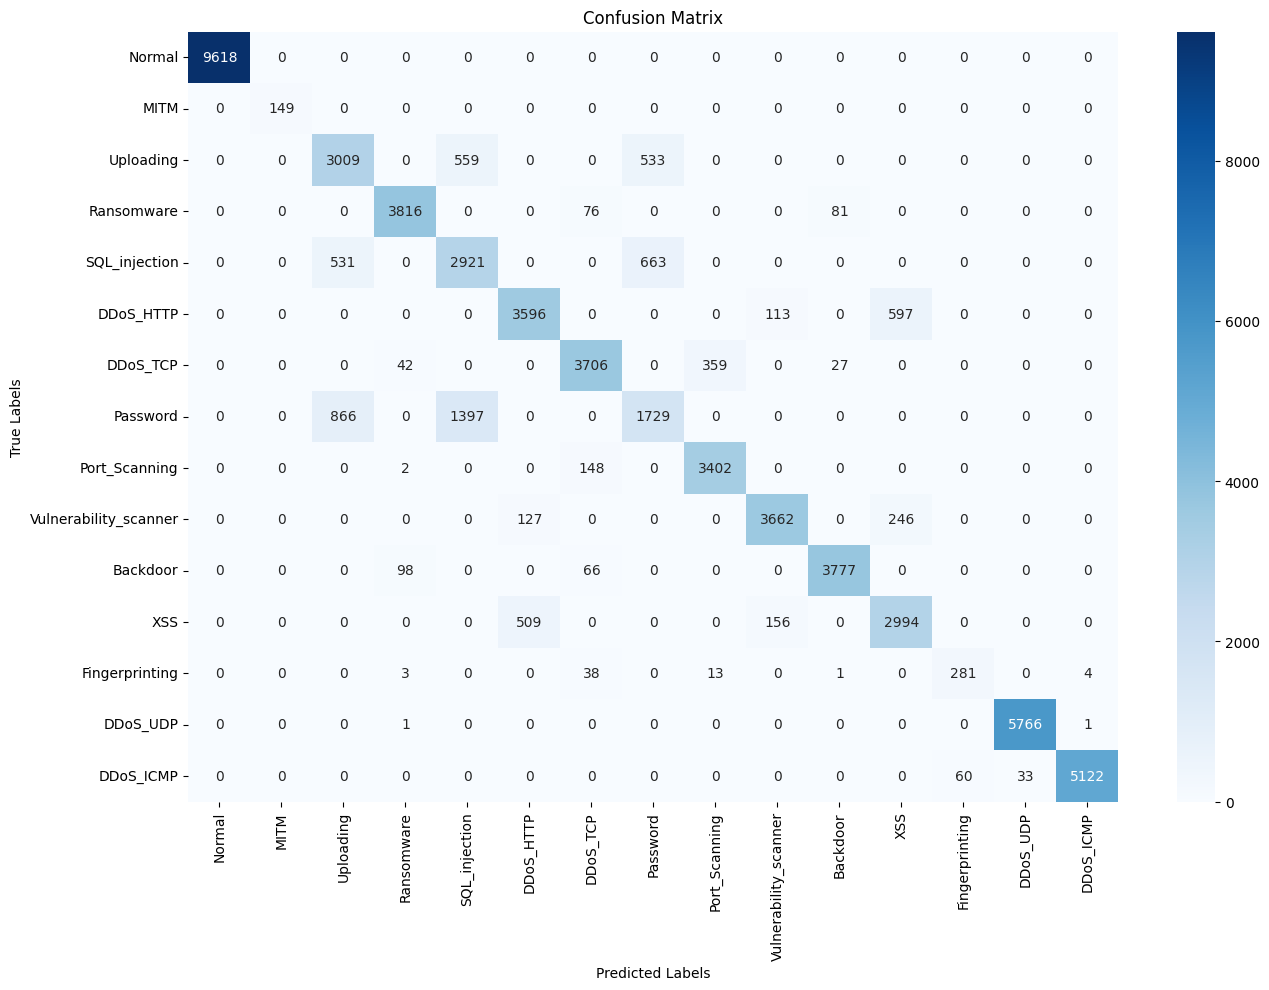

In [17]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

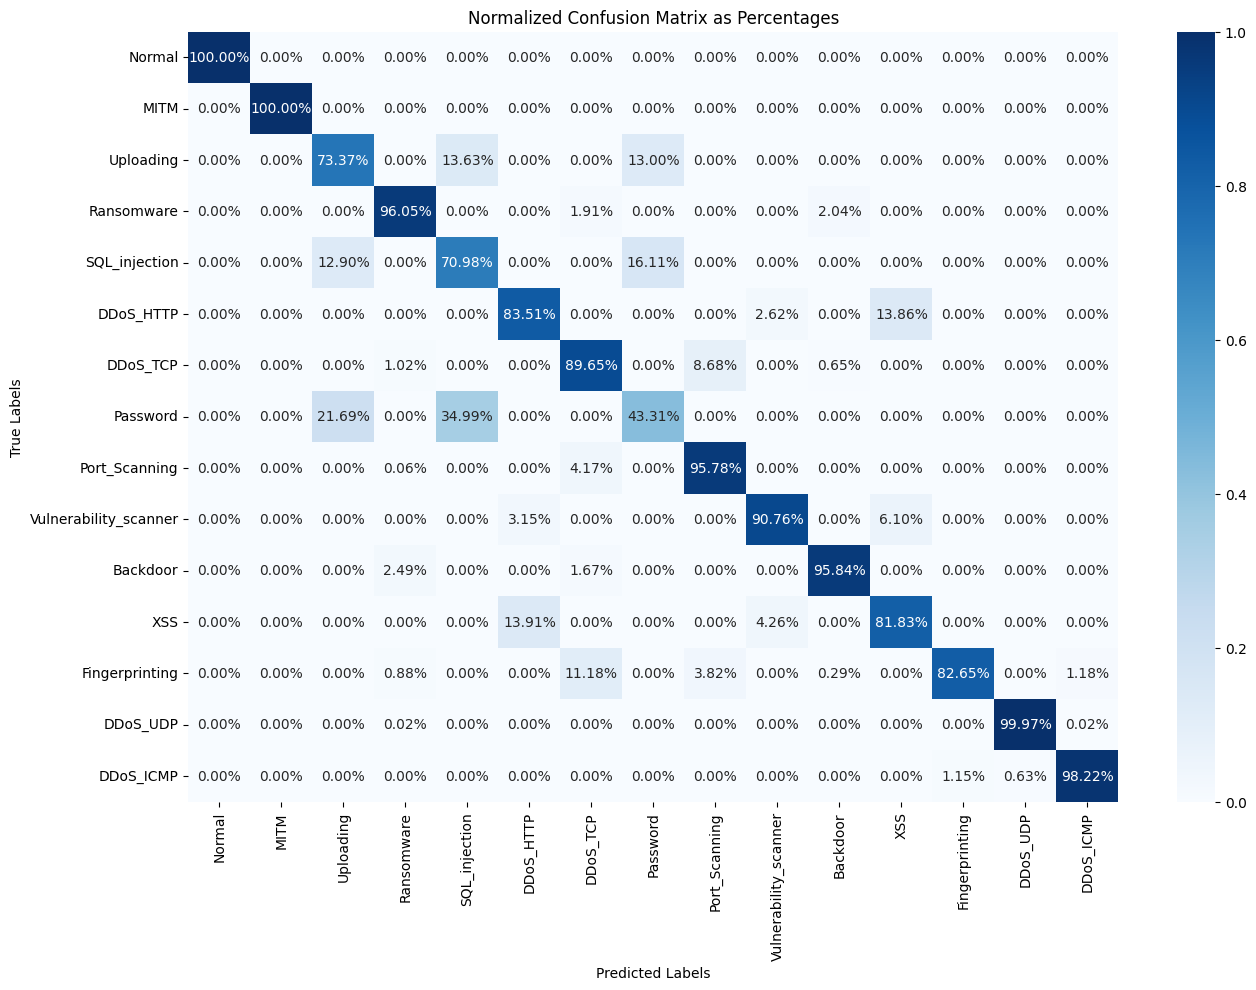

In [18]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()